# Week 2 — Day 1 — Exercises XP Gold

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'analysis_helpers.py').exists():
    if root == root.parent:
        raise FileNotFoundError('Ouvrir depuis Week2/day1 ou un sous-dossier')
    root = root.parent
sys.path.insert(0, str(root))
from analysis_helpers import *
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)


Source : chapitre Octopus 4785. Analyse des fichiers réellement fournis ; les limites de chaque jeu sont explicitées.

## Exercice 1 — Statistiques de base
Jeu Titanic, issu du concours Kaggle et fourni par le cours. Colonne choisie : `Age` (années).

In [2]:
titanic = load('train')
display(titanic['Age'].agg(['count','mean','median','std']).to_frame())
print('Âges absents :',titanic['Age'].isna().sum())

,Age
count,714.000000
mean,29.699118
median,28.000000
std,14.526497


Âges absents : 177


Écart-type d’échantillon (`ddof=1`). Les valeurs absentes sont exclues ; ces statistiques portent sur les âges renseignés et peuvent donc présenter un biais.

## Exercice 2 — Ventes structurées et avis libres

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106


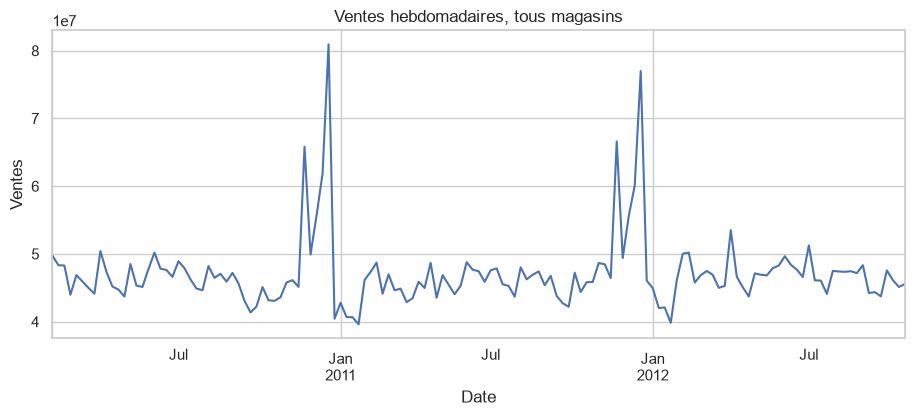

,total,moyenne_ligne,semaines
Store,,,
20,3.013978e+08,29508.301592,143
4,2.995440e+08,29161.210415,143
14,2.889999e+08,28784.851727,143
13,2.865177e+08,27355.136891,143
2,2.753824e+08,26898.070031,143
10,2.716177e+08,26332.303819,143
27,2.538559e+08,24826.984536,143
6,2.237561e+08,21913.243624,143
1,2.224028e+08,21710.543621,143


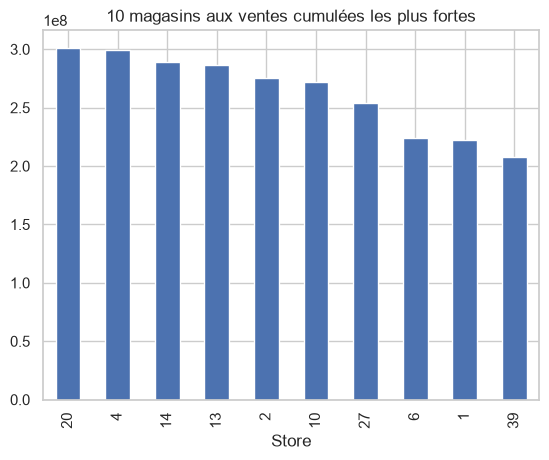

,count,mean,median
IsHoliday,,,
False,391909,15901.445069,7589.95
True,29661,17035.823187,7947.74


,count,sum,mean
Dept,,,
92,6435,4.839433e+08,75204.870531
95,6435,4.493202e+08,69824.423080
38,6435,3.931181e+08,61090.619568
72,6046,3.057252e+08,50566.515417
90,6435,2.910685e+08,45232.084488
40,6435,2.889360e+08,44900.702727
2,6435,2.806112e+08,43607.020113
91,6435,2.167817e+08,33687.910758
13,6435,1.973216e+08,30663.802634


Valeurs de ventes négatives : 1285


In [3]:
sales = load('Retail Data Analytics dataset','sales data-set.csv')
stores = load('Retail Data Analytics dataset','stores data-set.csv')
features = load('Retail Data Analytics dataset','Features data set.csv')
sales['Date'] = pd.to_datetime(sales['Date'], dayfirst=True)
features['Date'] = pd.to_datetime(features['Date'], dayfirst=True)
retail = sales.merge(stores,on='Store',validate='many_to_one').merge(features,on=['Store','Date','IsHoliday'],how='left',validate='many_to_one')
display(retail.head())
weekly = retail.groupby('Date')['Weekly_Sales'].sum()
weekly.plot(figsize=(11,4),title='Ventes hebdomadaires, tous magasins'); plt.ylabel('Ventes'); plt.show()
performance = retail.groupby('Store').agg(total=('Weekly_Sales','sum'), moyenne_ligne=('Weekly_Sales','mean'), semaines=('Date','nunique'))
display(performance.sort_values('total',ascending=False).head(10))
performance['total'].nlargest(10).plot.bar(title='10 magasins aux ventes cumulées les plus fortes');plt.show()
display(retail.groupby('IsHoliday')['Weekly_Sales'].agg(['count','mean','median']))
display(retail.groupby('Dept')['Weekly_Sales'].agg(['count','sum','mean']).sort_values('sum',ascending=False).head(10))
print('Valeurs de ventes négatives :', (sales['Weekly_Sales']<0).sum())

Le fichier décrit des ventes magasin-département-semaine, pas des achats individuels. Il permet d'observer saisonnalité et performance, mais pas de reconstruire un panier, une fidélité ou une fréquence d'achat client. Les moyennes par ligne ne sont pas des moyennes par client. Les fêtes, la taille des magasins et les départements ouverts sont des facteurs de confusion ; une association avec une promotion n'établit pas son effet causal.

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


Avis absents : 845


,part
sentiment_estimé,
positif,0.825008
neutre,0.156221
négatif,0.018771


,mot,occurrences
0,dress,10567
1,love,8951
2,size,8774
3,top,7418
4,fit,7326
5,like,7150
6,wear,6439
7,great,6117
8,too,6058
9,just,5608


Note moyenne : 4.196
Part recommandée : 0.822


Rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64

/var/folders/tn/21t5tzkd48z82_wfylsc12l00000gn/T/ipykernel_32678/4260897164.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  topics = pd.DataFrame({topic: reviews['Review Text'].fillna('').str.contains(pattern,case=False,regex=True)


,part des avis contenant le thème
taille_ajustement,0.0
matière,0.0
confort,0.0
couleur,0.0


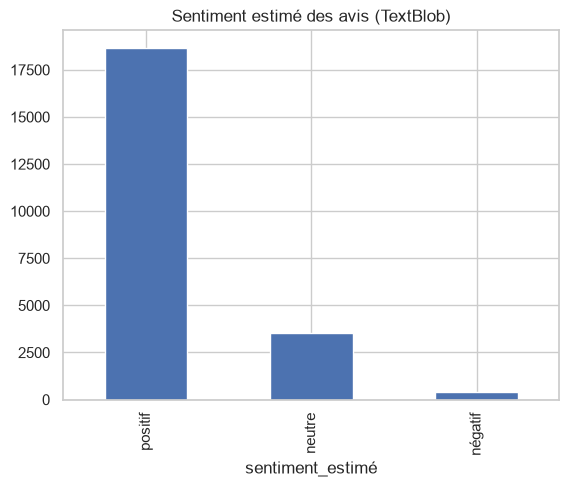

Rating,1,2,3,4,5
sentiment_estimé,,,,,
neutre,0.091886,0.166243,0.221374,0.235228,0.285270
négatif,0.275294,0.247059,0.237647,0.124706,0.115294
positif,0.020290,0.045827,0.103806,0.215376,0.614701


In [4]:
reviews = load("Women's E-Commerce Clothing Reviews")
display(reviews.head())
print('Avis absents :',reviews['Review Text'].isna().sum())
review_text, common_words = text_analysis(reviews['Review Text'])
display(review_text['sentiment_estimé'].value_counts(normalize=True).rename('part').to_frame())
display(pd.DataFrame(common_words.most_common(20),columns=['mot','occurrences']))
print('Note moyenne :',round(reviews['Rating'].mean(),3))
print('Part recommandée :',round(reviews['Recommended IND'].mean(),3))
display(reviews['Rating'].value_counts().sort_index())
topics = pd.DataFrame({topic: reviews['Review Text'].fillna('').str.contains(pattern,case=False,regex=True)
 for topic,pattern in {'taille_ajustement':r'(size|fit|small|large)','matière':r'(fabric|material|cotton|silk)','confort':r'(comfortable|comfort|soft)','couleur':r'(color|colour)'}.items()})
display(topics.mean().sort_values(ascending=False).rename('part des avis contenant le thème').to_frame())
review_text['sentiment_estimé'].value_counts().plot.bar(title='Sentiment estimé des avis (TextBlob)');plt.show()
display(pd.crosstab(review_text['sentiment_estimé'],reviews.loc[review_text.index,'Rating'],normalize='index'))

Les notes et recommandations mesurent une satisfaction déclarée ; les textes expliquent notamment l'ajustement, la matière et le confort. Les proportions de thèmes peuvent se chevaucher. La polarité TextBlob est une heuristique anglaise, sensible à la négation, au sarcasme et au vocabulaire du vêtement ; elle n'est pas une étiquette validée. Les notes servent de confrontation, pas de preuve que l'algorithme est exact. Les deux datasets ne partagent aucune clé client : aucune jointure individuelle n'est justifiée. Les ventes décrivent le « combien/quand/où », les avis apportent des raisons possibles.

## Exercice 3 — Exploration E-Commerce

In [5]:
commerce = load('E-Commerce Dataset',encoding='latin1',dtype={'InvoiceNo':'string','StockCode':'string','CustomerID':'string'})
commerce['InvoiceDate'] = pd.to_datetime(commerce['InvoiceDate'])
print('Dimensions :',commerce.shape); print('Colonnes :',list(commerce.columns))
display(commerce.head()); commerce.info()
display(commerce.isna().sum().to_frame('manquants'))
print('Factures annulées :',commerce['InvoiceNo'].str.startswith('C').sum())
print('Lignes quantité négative :',(commerce['Quantity']<0).sum())

Dimensions : (541909, 8)
Colonnes : ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(2), string(3)
memory usage: 33.1 MB


,manquants
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Factures annulées : 9288
Lignes quantité négative : 10624


Éléments structurés : `InvoiceNo`, `StockCode`, `CustomerID` sont des identifiants ; `Quantity`, `UnitPrice` des mesures ; `InvoiceDate` une date-heure ; `Country` une catégorie. `Description` est du texte libre stocké dans une table : sa colonne est structurée mais son contenu est peu normalisé. Des avis clients et descriptions détaillées compléteraient les transactions via une clé produit et éventuellement une période ; on pourrait relier thèmes d'avis et retours, sans supposer une causalité. Il faut contrôler les valeurs absentes et le consentement, et ne pas supprimer les annulations sans documenter l'objectif.

## Exercice 4 — Trafic Metro Interstate

In [6]:
traffic = load('Metro Interstate Traffic Volume',keep_default_na=False)
traffic['date_time'] = pd.to_datetime(traffic['date_time'])
display(traffic.head()); traffic.info()
display(traffic[['weather_main','weather_description']].nunique().to_frame('modalités'))

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              48204 non-null  str           
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  str           
 6   weather_description  48204 non-null  str           
 7   date_time            48204 non-null  datetime64[us]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(2), str(3)
memory usage: 3.3 MB


,modalités
weather_main,11
weather_description,38


Toutes les colonnes ont un schéma tabulaire. `date_time` est temporelle ; `traffic_volume`, `clouds_all` sont des comptes/pourcentages ; `temp` (kelvins), `rain_1h`, `snow_1h` des mesures continues ; `holiday`, `weather_main` des catégories. `weather_description` est une courte description issue d'un vocabulaire limité : ici, elle fonctionne comme catégorie structurée, contrairement à un long rapport météo narratif. `None` dans holiday signifie absence de fête ; il est préservé plutôt qu'interprété comme donnée manquante. Le dataset mesure le trafic routier, pas une fréquentation de métro malgré son titre.

## Exercice 5 — MovieLens 20M

In [7]:
# L’archive fournie contient rating.csv (singulier), pas ratings.csv.
ratings_path = DATA / 'MovieLens 20M Dataset' / 'rating.csv'
ratings_head = pd.read_csv(ratings_path,nrows=5)
display(ratings_head)
rows = 0
for chunk in pd.read_csv(ratings_path,chunksize=500_000):
    assert chunk[['userId','movieId','rating','timestamp']].notna().all().all()
    assert chunk['rating'].between(.5,5).all()
    pd.to_datetime(chunk['timestamp'],errors='raise')
    rows += len(chunk)
print('Nombre de notes vérifiées :',rows)
assert rows == 20_000_263

,userId,movieId,rating,timestamp
0,1,2,3.5,2005-04-02 23:53:47
1,1,29,3.5,2005-04-02 23:31:16
2,1,32,3.5,2005-04-02 23:33:39
3,1,47,3.5,2005-04-02 23:32:07
4,1,50,3.5,2005-04-02 23:29:40


Nombre de notes vérifiées : 20000263


`userId` et `movieId` sont des clés nominales ; `rating` est une note ordinale à pas de 0,5 ; `timestamp` est une date-heure dans cette archive. Chaque ligne respecte le même schéma et décrit une note utilisateur-film : il s'agit de données structurées. Lecture par blocs pour éviter de charger 20 millions de lignes à la fois.

## Exercice 6 — Catalogue synthétique Faker

In [8]:
from faker import Faker
from random import Random
fake = Faker('en_US'); fake.seed_instance(2026)
rng = Random(2026)
products = pd.DataFrame([{'product_id':i,'name':fake.unique.catch_phrase(),'description':fake.text(max_nb_chars=180), 'price':rng.randint(100,100000)/100} for i in range(1,501)])
assert len(products)==500 and products['product_id'].is_unique
assert products['name'].is_unique and products['price'].gt(0).all()
assert products[['name','description']].notna().all().all()
products.to_csv(RESULTS/'synthetic_products.csv',index=False)
display(products.head())
print('500 produits fictifs, identifiants uniques, prix positifs.')

,product_id,name,description,price
0,1,Decentralized foreground middleware,This thus perform inside. Natural room should ...,157.13
1,2,Customizable interactive middleware,Dark story act change think whether. Until gro...,419.75
2,3,Seamless dedicated encryption,And national environmental serious ground abov...,659.65
3,4,Business-focused grid-enabled project,Agent live radio. For building we occur source...,671.85
4,5,Grass-roots bandwidth-monitored data-warehouse,West these population. Nation street suffer co...,849.29


500 produits fictifs, identifiants uniques, prix positifs.
